2026-10-29 22:37:15.907 | INFO     | __main__:subgraph_strip_node:17 - 调用子图中的strip结点
2026-10-29 22:37:15.908 | INFO     | __main__:subgraph_punctuated_node:26 - 调用子图中的punctuated结点


{'raw_text': '   langgraph真有意思    ', 'stripped_text': 'langgraph真有意思', 'punctuated_text': 'langgraph真有意思。'}


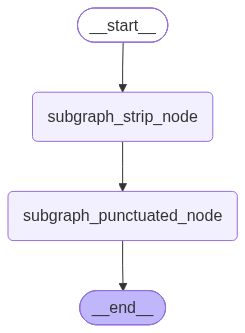

In [4]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from loguru import logger

# 1.构建子图
# 1.1声明子图的状态
class SubgraphState(TypedDict):
    raw_text: str  # 未清洗的文本
    stripped_text: str   # 去除收尾的空格
    punctuated_text: str # 句尾添加句号

# 1.2 声明子图的结点
# 去除空格的结点
def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()
    logger.info("调用子图中的strip结点")
    return {
        "stripped_text": stripped_text
    }

# 1.3 添加句号的结点
def subgraph_punctuated_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + '。'
    logger.info("调用子图中的punctuated结点")
    return {
        "punctuated_text": punctuated_text
    }

# 1.4 构建子图
builder = StateGraph(state_schema = SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuated_node", subgraph_punctuated_node)
builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuated_node")
builder.add_edge("subgraph_punctuated_node", END)

subgraph = builder.compile()

res = subgraph.invoke({
    "raw_text": "   langgraph真有意思    "
})

print(res)

from IPython.display import display
display(subgraph)

2026-10-29 22:37:38.564 | INFO     | __main__:subgraph_strip_node:17 - 调用子图中的strip结点
2026-10-29 22:37:38.565 | INFO     | __main__:subgraph_punctuated_node:26 - 调用子图中的punctuated结点


{'input_text': '  langgraph666   ', 'cleared_text': 'langgraph666。'}


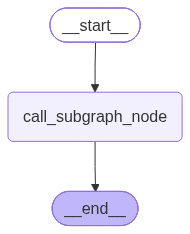

In [6]:
# 2.构建父图
# 2.1 声明状态
class ParentState(TypedDict):
    input_text: str
    cleared_text: str

# 2.2 声明结点 调用子图结点
def call_subgraph_node(state: ParentState) -> ParentState:
    input_text = state["input_text"]
    res = subgraph.invoke({"raw_text": input_text})
    cleared_text = res["punctuated_text"]
    return {
        "cleared_text": cleared_text
    }

# 2.3 构建父图
parent_builder = StateGraph(state_schema = ParentState)
parent_builder.add_node("call_subgraph_node", call_subgraph_node)
parent_builder.add_edge(START, "call_subgraph_node")
parent_builder.add_edge("call_subgraph_node", END)

parent_graph = parent_builder.compile()

# 2.4 调用父图 内部函数会调用子图
res = parent_graph.invoke({"input_text": "  langgraph666   "})
print(res)

from IPython.display import display
display(parent_graph)